In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Charger les données préparées
X_train = pd.read_csv("../../data/X_train.csv")
X_test = pd.read_csv("../../data/X_test.csv")

y_train = pd.read_csv("../../data/y_train.csv").squeeze()
y_test = pd.read_csv("../../data/y_test.csv").squeeze()

# Vérifier les dimensions
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (43194, 18)
X_test : (10799, 18)
y_train : (43194,)
y_test : (10799,)


In [2]:
# Baseline : prédire la prochaine latence
# en utilisant la latence actuelle

y_pred_baseline = X_test["rtt_avg_ms"]

# Calcul des métriques
mae_baseline = mean_absolute_error(
    y_test, y_pred_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

r2_baseline = r2_score(
    y_test, y_pred_baseline
)

# Afficher les résultats
print("===== RÉSULTATS BASELINE =====")

print(f"MAE  : {mae_baseline:.4f} ms")
print(f"RMSE : {rmse_baseline:.4f} ms")
print(f"R²   : {r2_baseline:.4f}")

===== RÉSULTATS BASELINE =====
MAE  : 0.5807 ms
RMSE : 1.0008 ms
R²   : 0.0394


In [3]:
from sklearn.ensemble import RandomForestRegressor

# Création du modèle
rf_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Entraînement
rf_model.fit(X_train, y_train)

print("Entraînement Random Forest terminé !")

Entraînement Random Forest terminé !


In [4]:
# Prédictions sur les données de test
y_pred_rf = rf_model.predict(X_test)

# Calcul des métriques
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

# Affichage
print("===== RÉSULTATS RANDOM FOREST =====")

print(f"MAE  : {mae_rf:.4f} ms")
print(f"RMSE : {rmse_rf:.4f} ms")
print(f"R²   : {r2_rf:.4f}")

===== RÉSULTATS RANDOM FOREST =====
MAE  : 1.1255 ms
RMSE : 1.3960 ms
R²   : -0.8689


In [5]:
# Comparaison des valeurs réelles et prédites

comparaison = pd.DataFrame({
    "Latence_actuelle": X_test["rtt_avg_ms"],
    "Latence_reelle": y_test,
    "Prediction_Baseline": y_pred_baseline,
    "Prediction_RF": y_pred_rf
})

display(comparaison.head(15))

print("\nStatistiques des prédictions Random Forest :")
print(pd.Series(y_pred_rf).describe())

print("\nStatistiques des valeurs réelles :")
print(y_test.describe())

,Latence_actuelle,Latence_reelle,Prediction_Baseline,Prediction_RF
0,10.200,11.400,10.200,13.103568
1,11.400,21.400,11.400,13.112884
2,21.400,11.400,21.400,13.214607
3,11.400,10.600,11.400,12.839008
4,10.600,11.400,10.600,12.687016
5,11.400,11.500,11.400,12.261865
6,11.500,10.100,11.500,11.862852
7,10.100,11.300,10.100,12.204879
8,11.300,10.400,11.300,12.229928
9,10.400,10.900,10.400,12.501729



Statistiques des prédictions Random Forest :
count    10799.000000
mean        11.794362
std          0.961275
min         10.726563
25%         11.284112
50%         11.560534
75%         11.945192
max         33.576969
dtype: float64

Statistiques des valeurs réelles :
count    10799.000000
mean        10.840708
std          1.021187
min          9.300000
25%         10.300000
50%         10.600000
75%         11.000000
max         34.200000
Name: rtt_future, dtype: float64


In [6]:
# Comparaison des distributions Train / Test

print("===== CIBLE : LATENCE FUTURE =====")

print("\nEntraînement :")
print(y_train.describe())

print("\nTest :")
print(y_test.describe())


print("\n===== LATENCE ACTUELLE =====")

print("\nEntraînement :")
print(X_train["rtt_avg_ms"].describe())

print("\nTest :")
print(X_test["rtt_avg_ms"].describe())


# Vérifier si le modèle surapprend
y_pred_rf_train = rf_model.predict(X_train)

print("\n===== PERFORMANCE SUR TRAIN =====")

print("MAE Train :",
      mean_absolute_error(y_train, y_pred_rf_train))

print("MAE Test :",
      mean_absolute_error(y_test, y_pred_rf))

===== CIBLE : LATENCE FUTURE =====

Entraînement :
count    43194.000000
mean        13.014653
std          5.743342
min          9.700000
25%         10.700000
50%         11.300000
75%         13.000000
max        288.600000
Name: rtt_future, dtype: float64

Test :
count    10799.000000
mean        10.840708
std          1.021187
min          9.300000
25%         10.300000
50%         10.600000
75%         11.000000
max         34.200000
Name: rtt_future, dtype: float64

===== LATENCE ACTUELLE =====

Entraînement :
count    43194.000000
mean        13.012499
std          5.740725
min          9.700000
25%         10.700000
50%         11.300000
75%         13.000000
max        288.600000
Name: rtt_avg_ms, dtype: float64

Test :
count    10799.000000
mean        10.842277
std          1.020297
min          9.300000
25%         10.300000
50%         10.600000
75%         11.000000
max         34.200000
Name: rtt_avg_ms, dtype: float64

===== PERFORMANCE SUR TRAIN =====
MAE Train : 0.74

In [7]:
# Baseline sur Train
y_pred_baseline_train = X_train["rtt_avg_ms"]

# Baseline sur Test
y_pred_baseline_test = X_test["rtt_avg_ms"]

# Tableau comparatif des performances
resultats = pd.DataFrame({
    "Modele": ["Baseline", "Random Forest"],
    "MAE_Train": [
        mean_absolute_error(y_train, y_pred_baseline_train),
        mean_absolute_error(y_train, y_pred_rf_train)
    ],
    "MAE_Test": [
        mean_absolute_error(y_test, y_pred_baseline_test),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    "RMSE_Test": [
        np.sqrt(mean_squared_error(y_test, y_pred_baseline_test)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "R2_Test": [
        r2_score(y_test, y_pred_baseline_test),
        r2_score(y_test, y_pred_rf)
    ]
})

display(resultats.round(4))

,Modele,MAE_Train,MAE_Test,RMSE_Test,R2_Test
0,Baseline,1.5108,0.5807,1.0008,0.0394
1,Random Forest,0.7411,1.1255,1.3960,-0.8689


In [8]:
features_reduites = [
    "rtt_avg_ms",
    "rtt_min_ms",
    "rtt_max_ms",
    "rtt_median_ms",
    "rtt_stddev_ms",
    "jitter_ms",
    "packet_loss_pct",
    "gateway_rtt_avg_ms",
    "gateway_jitter_ms"
]

X_train_reduit = X_train[features_reduites].copy()
X_test_reduit = X_test[features_reduites].copy()

print("X_train réduit :", X_train_reduit.shape)
print("X_test réduit :", X_test_reduit.shape)

X_train réduit : (43194, 9)
X_test réduit : (10799, 9)


In [9]:
# Création du modèle réduit
rf_model_reduit = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Entraînement
rf_model_reduit.fit(X_train_reduit, y_train)

print("Entraînement Random Forest réduit terminé !")

Entraînement Random Forest réduit terminé !


In [10]:
# Prédictions sur le jeu de test
y_pred_rf_reduit = rf_model_reduit.predict(X_test_reduit)

# Calcul des métriques
mae_rf_reduit = mean_absolute_error(y_test, y_pred_rf_reduit)

rmse_rf_reduit = np.sqrt(
    mean_squared_error(y_test, y_pred_rf_reduit)
)

r2_rf_reduit = r2_score(y_test, y_pred_rf_reduit)

# Affichage
print("===== RANDOM FOREST : 9 VARIABLES =====")
print(f"MAE  : {mae_rf_reduit:.4f} ms")
print(f"RMSE : {rmse_rf_reduit:.4f} ms")
print(f"R²   : {r2_rf_reduit:.4f}")

===== RANDOM FOREST : 9 VARIABLES =====
MAE  : 0.8393 ms
RMSE : 1.1042 ms
R²   : -0.1692


In [11]:
features_6 = [
    "rtt_avg_ms",
    "rtt_stddev_ms",
    "jitter_ms",
    "packet_loss_pct",
    "gateway_rtt_avg_ms",
    "gateway_jitter_ms"
]

X_train_6 = X_train[features_6].copy()
X_test_6 = X_test[features_6].copy()

print("X_train :", X_train_6.shape)
print("X_test :", X_test_6.shape)

X_train : (43194, 6)
X_test : (10799, 6)


In [12]:
# Création du modèle Random Forest (6 variables)
rf_model_6 = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Entraînement
rf_model_6.fit(X_train_6, y_train)

print("Entraînement Random Forest (6 variables) terminé !")

Entraînement Random Forest (6 variables) terminé !


In [13]:
# Prédictions
y_pred_rf_6 = rf_model_6.predict(X_test_6)

# Calcul des métriques
mae_rf_6 = mean_absolute_error(y_test, y_pred_rf_6)

rmse_rf_6 = np.sqrt(
    mean_squared_error(y_test, y_pred_rf_6)
)

r2_rf_6 = r2_score(y_test, y_pred_rf_6)

# Affichage
print("===== RANDOM FOREST : 6 VARIABLES =====")
print(f"MAE  : {mae_rf_6:.4f} ms")
print(f"RMSE : {rmse_rf_6:.4f} ms")
print(f"R²   : {r2_rf_6:.4f}")

===== RANDOM FOREST : 6 VARIABLES =====
MAE  : 0.8387 ms
RMSE : 1.1098 ms
R²   : -0.1811


In [14]:
from sklearn.linear_model import LinearRegression

# Création du modèle
lr_model = LinearRegression()

# Entraînement avec les 9 variables
lr_model.fit(X_train_reduit, y_train)

print("Entraînement Linear Regression terminé !")

Entraînement Linear Regression terminé !


In [15]:
# Prédictions sur les données de test
y_pred_lr = lr_model.predict(X_test_reduit)

# Calcul des métriques
mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

r2_lr = r2_score(y_test, y_pred_lr)

# Affichage
print("===== RÉSULTATS LINEAR REGRESSION =====")

print(f"MAE  : {mae_lr:.4f} ms")
print(f"RMSE : {rmse_lr:.4f} ms")
print(f"R²   : {r2_lr:.4f}")

===== RÉSULTATS LINEAR REGRESSION =====
MAE  : 0.9407 ms
RMSE : 1.1597 ms
R²   : -0.2898


In [16]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

X_train_lag = pd.read_csv("../../data/X_train_lag.csv")
X_test_lag = pd.read_csv("../../data/X_test_lag.csv")

y_train_lag = pd.read_csv("../../data/y_train_lag.csv").squeeze()
y_test_lag = pd.read_csv("../../data/y_test_lag.csv").squeeze()

print("X_train :", X_train_lag.shape)
print("X_test :", X_test_lag.shape)
print("y_train :", y_train_lag.shape)
print("y_test :", y_test_lag.shape)

X_train : (41818, 15)
X_test : (10455, 15)
y_train : (41818,)
y_test : (10455,)


In [17]:
y_pred_baseline_lag = X_test_lag["rtt_avg_ms"]

mae_baseline_lag = mean_absolute_error(
    y_test_lag, y_pred_baseline_lag
)

rmse_baseline_lag = np.sqrt(
    mean_squared_error(y_test_lag, y_pred_baseline_lag)
)

r2_baseline_lag = r2_score(
    y_test_lag, y_pred_baseline_lag
)

print("===== BASELINE AVEC LE NOUVEAU TEST =====")
print("MAE :", round(mae_baseline_lag, 4))
print("RMSE :", round(rmse_baseline_lag, 4))
print("R² :", round(r2_baseline_lag, 4))

===== BASELINE AVEC LE NOUVEAU TEST =====
MAE : 0.5803
RMSE : 0.9974
R² : 0.0461


In [18]:
from sklearn.ensemble import RandomForestRegressor

rf_lag = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_lag.fit(X_train_lag, y_train_lag)

y_pred_rf_lag = rf_lag.predict(X_test_lag)

print("Entraînement terminé.")

Entraînement terminé.


In [19]:
mae_rf_lag = mean_absolute_error(
    y_test_lag, y_pred_rf_lag
)

rmse_rf_lag = np.sqrt(
    mean_squared_error(y_test_lag, y_pred_rf_lag)
)

r2_rf_lag = r2_score(
    y_test_lag, y_pred_rf_lag
)

print("===== RANDOM FOREST AVEC HISTORIQUES =====")
print("MAE :", round(mae_rf_lag, 4))
print("RMSE :", round(rmse_rf_lag, 4))
print("R² :", round(r2_rf_lag, 4))

===== RANDOM FOREST AVEC HISTORIQUES =====
MAE : 0.6533
RMSE : 0.9268
R² : 0.1764


In [20]:
features_courantes = [
    "rtt_avg_ms",
    "rtt_stddev_ms",
    "jitter_ms",
    "packet_loss_pct",
    "gateway_rtt_avg_ms",
    "gateway_jitter_ms"
]

X_train_6_lag = X_train_lag[features_courantes]
X_test_6_lag = X_test_lag[features_courantes]

rf_6_lag = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_6_lag.fit(X_train_6_lag, y_train_lag)

y_pred_rf_6_lag = rf_6_lag.predict(X_test_6_lag)

mae_rf_6_lag = mean_absolute_error(
    y_test_lag, y_pred_rf_6_lag
)

rmse_rf_6_lag = np.sqrt(
    mean_squared_error(y_test_lag, y_pred_rf_6_lag)
)

r2_rf_6_lag = r2_score(
    y_test_lag, y_pred_rf_6_lag
)

print("===== RANDOM FOREST - 6 VARIABLES ACTUELLES =====")
print("MAE :", round(mae_rf_6_lag, 4))
print("RMSE :", round(rmse_rf_6_lag, 4))
print("R² :", round(r2_rf_6_lag, 4))

===== RANDOM FOREST - 6 VARIABLES ACTUELLES =====
MAE : 0.8378
RMSE : 1.1047
R² : -0.17


In [21]:
comparaison = pd.DataFrame({
    "Modèle": [
        "Baseline",
        "Random Forest - 6 variables",
        "Random Forest - 15 variables"
    ],
    "MAE": [
        mae_baseline_lag,
        mae_rf_6_lag,
        mae_rf_lag
    ],
    "RMSE": [
        rmse_baseline_lag,
        rmse_rf_6_lag,
        rmse_rf_lag
    ],
    "R2": [
        r2_baseline_lag,
        r2_rf_6_lag,
        r2_rf_lag
    ]
})

display(comparaison.round(4))

,Modèle,MAE,RMSE,R2
0,Baseline,0.5803,0.9974,0.0461
1,Random Forest - 6 variables,0.8378,1.1047,-0.1700
2,Random Forest - 15 variables,0.6533,0.9268,0.1764


In [22]:
# Calculer les erreurs absolues
erreurs_baseline = np.abs(
    y_test_lag.to_numpy() - y_pred_baseline_lag.to_numpy()
)

erreurs_rf = np.abs(
    y_test_lag.to_numpy() - y_pred_rf_lag
)

# Comparer plusieurs indicateurs d'erreur
analyse_erreurs = pd.DataFrame({
    "Indicateur": [
        "Erreur médiane",
        "90e percentile",
        "95e percentile",
        "Erreur maximale",
        "Nombre d'erreurs > 2 ms",
        "Nombre d'erreurs > 5 ms"
    ],
    "Baseline": [
        np.median(erreurs_baseline),
        np.percentile(erreurs_baseline, 90),
        np.percentile(erreurs_baseline, 95),
        np.max(erreurs_baseline),
        np.sum(erreurs_baseline > 2),
        np.sum(erreurs_baseline > 5)
    ],
    "Random Forest": [
        np.median(erreurs_rf),
        np.percentile(erreurs_rf, 90),
        np.percentile(erreurs_rf, 95),
        np.max(erreurs_rf),
        np.sum(erreurs_rf > 2),
        np.sum(erreurs_rf > 5)
    ]
})

display(analyse_erreurs.round(4))

,Indicateur,Baseline,Random Forest
0,Erreur médiane,0.3000,0.5544
1,90e percentile,1.4000,1.1889
2,95e percentile,1.9432,1.4768
3,Erreur maximale,19.8330,19.6859
4,Nombre d'erreurs > 2 ms,459.0000,194.0000
5,Nombre d'erreurs > 5 ms,30.0000,18.0000


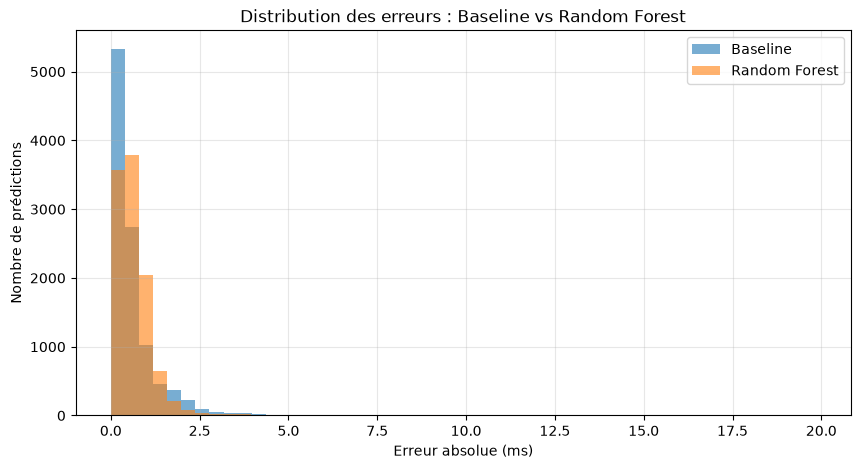

In [24]:
import matplotlib.pylab as plt
plt.figure(figsize=(10, 5))

plt.hist(
    erreurs_baseline,
    bins=50,
    alpha=0.6,
    label="Baseline"
)

plt.hist(
    erreurs_rf,
    bins=50,
    alpha=0.6,
    label="Random Forest"
)

plt.xlabel("Erreur absolue (ms)")
plt.ylabel("Nombre de prédictions")
plt.title("Distribution des erreurs : Baseline vs Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
# Construire un tableau comparatif
resultats = pd.DataFrame({
    "latence_reelle": y_test_lag.to_numpy(),
    "prediction_baseline": y_pred_baseline_lag.to_numpy(),
    "prediction_rf": y_pred_rf_lag
})

# Identifier les périodes où la latence réelle dépasse 15 ms
pics = resultats[
    resultats["latence_reelle"] > 15
].copy()

# Calculer les erreurs sur ces périodes
pics["erreur_baseline"] = abs(
    pics["latence_reelle"] - pics["prediction_baseline"]
)

pics["erreur_rf"] = abs(
    pics["latence_reelle"] - pics["prediction_rf"]
)

print("Nombre de pics :", len(pics))

print("\nMAE pendant les pics :")
print("Baseline :", round(pics["erreur_baseline"].mean(), 4))
print("Random Forest :", round(pics["erreur_rf"].mean(), 4))

print("\nRMSE pendant les pics :")
print(
    "Baseline :",
    round(np.sqrt((pics["erreur_baseline"]**2).mean()), 4)
)
print(
    "Random Forest :",
    round(np.sqrt((pics["erreur_rf"]**2).mean()), 4)
)

Nombre de pics : 140

MAE pendant les pics :
Baseline : 2.1728
Random Forest : 2.348

RMSE pendant les pics :
Baseline : 3.8856
Random Forest : 3.9697


In [26]:
X_train_lag5 = pd.read_csv("../../data/X_train_lag5.csv")
X_test_lag5 = pd.read_csv("../../data/X_test_lag5.csv")

y_train_lag5 = pd.read_csv("../../data/y_train_lag5.csv").squeeze()
y_test_lag5 = pd.read_csv("../../data/y_test_lag5.csv").squeeze()

print("X_train :", X_train_lag5.shape)
print("X_test :", X_test_lag5.shape)
print("y_train :", y_train_lag5.shape)
print("y_test :", y_test_lag5.shape)

X_train : (40908, 21)
X_test : (10228, 21)
y_train : (40908,)
y_test : (10228,)


In [27]:
y_pred_baseline_lag5 = X_test_lag5["rtt_avg_ms"]

mae_baseline_lag5 = mean_absolute_error(
    y_test_lag5, y_pred_baseline_lag5
)

rmse_baseline_lag5 = np.sqrt(
    mean_squared_error(y_test_lag5, y_pred_baseline_lag5)
)

r2_baseline_lag5 = r2_score(
    y_test_lag5, y_pred_baseline_lag5
)

print("===== BASELINE - 5 HISTORIQUES =====")
print("MAE :", round(mae_baseline_lag5, 4))
print("RMSE :", round(rmse_baseline_lag5, 4))
print("R² :", round(r2_baseline_lag5, 4))

===== BASELINE - 5 HISTORIQUES =====
MAE : 0.5798
RMSE : 0.9968
R² : 0.0503


In [28]:
rf_lag5 = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_lag5.fit(X_train_lag5, y_train_lag5)

y_pred_rf_lag5 = rf_lag5.predict(X_test_lag5)

print("Entraînement terminé.")

Entraînement terminé.


In [29]:
mae_rf_lag5 = mean_absolute_error(
    y_test_lag5, y_pred_rf_lag5
)

rmse_rf_lag5 = np.sqrt(
    mean_squared_error(y_test_lag5, y_pred_rf_lag5)
)

r2_rf_lag5 = r2_score(
    y_test_lag5, y_pred_rf_lag5
)

print("===== RANDOM FOREST - 5 HISTORIQUES =====")
print("MAE :", round(mae_rf_lag5, 4))
print("RMSE :", round(rmse_rf_lag5, 4))
print("R² :", round(r2_rf_lag5, 4))

===== RANDOM FOREST - 5 HISTORIQUES =====
MAE : 0.6167
RMSE : 0.8943
R² : 0.2356


In [30]:
X3_train = pd.read_csv("../../data/X3_train_commun.csv")
X3_test = pd.read_csv("../../data/X3_test_commun.csv")

X5_train = pd.read_csv("../../data/X5_train_commun.csv")
X5_test = pd.read_csv("../../data/X5_test_commun.csv")

y_train_commun = pd.read_csv(
    "../../data/y_train_commun.csv"
).squeeze()

y_test_commun = pd.read_csv(
    "../../data/y_test_commun.csv"
).squeeze()

print("X3 train :", X3_train.shape)
print("X3 test :", X3_test.shape)
print("X5 train :", X5_train.shape)
print("X5 test :", X5_test.shape)
print("y train :", y_train_commun.shape)
print("y test :", y_test_commun.shape)

X3 train : (40908, 15)
X3 test : (10228, 15)
X5 train : (40908, 21)
X5 test : (10228, 21)
y train : (40908,)
y test : (10228,)


In [31]:
# Random Forest avec 3 historiques
rf3_commun = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf3_commun.fit(X3_train, y_train_commun)

y_pred_rf3_commun = rf3_commun.predict(X3_test)


# Random Forest avec 5 historiques
rf5_commun = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf5_commun.fit(X5_train, y_train_commun)

y_pred_rf5_commun = rf5_commun.predict(X5_test)

print("Les deux modèles sont entraînés.")

Les deux modèles sont entraînés.


In [32]:
resultats_communs = pd.DataFrame({
    "Modèle": [
        "Baseline",
        "Random Forest - 3 historiques",
        "Random Forest - 5 historiques"
    ],
    "MAE": [
        mean_absolute_error(
            y_test_commun, X3_test["rtt_avg_ms"]
        ),
        mean_absolute_error(
            y_test_commun, y_pred_rf3_commun
        ),
        mean_absolute_error(
            y_test_commun, y_pred_rf5_commun
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            y_test_commun, X3_test["rtt_avg_ms"]
        )),
        np.sqrt(mean_squared_error(
            y_test_commun, y_pred_rf3_commun
        )),
        np.sqrt(mean_squared_error(
            y_test_commun, y_pred_rf5_commun
        ))
    ],
    "R2": [
        r2_score(y_test_commun, X3_test["rtt_avg_ms"]),
        r2_score(y_test_commun, y_pred_rf3_commun),
        r2_score(y_test_commun, y_pred_rf5_commun)
    ]
})

display(resultats_communs.round(4))

,Modèle,MAE,RMSE,R2
0,Baseline,0.5798,0.9968,0.0503
1,Random Forest - 3 historiques,0.6526,0.9289,0.1754
2,Random Forest - 5 historiques,0.6167,0.8943,0.2356


In [33]:
# Construire un tableau avec les prédictions des trois modèles
resultats_pics = pd.DataFrame({
    "latence_reelle": y_test_commun.to_numpy(),
    "baseline": X3_test["rtt_avg_ms"].to_numpy(),
    "rf_3": y_pred_rf3_commun,
    "rf_5": y_pred_rf5_commun
})

# Identifier les pics de latence
pics_communs = resultats_pics[
    resultats_pics["latence_reelle"] > 15
].copy()

print("Nombre de pics :", len(pics_communs))

# Calculer les métriques pendant les pics
for modele in ["baseline", "rf_3", "rf_5"]:

    erreurs = (
        pics_communs["latence_reelle"]
        - pics_communs[modele]
    )

    mae = np.mean(np.abs(erreurs))
    rmse = np.sqrt(np.mean(erreurs ** 2))

    print(f"\n{modele.upper()}")
    print("MAE :", round(mae, 4))
    print("RMSE :", round(rmse, 4))

Nombre de pics : 138

BASELINE
MAE : 2.1202
RMSE : 3.8236

RF_3
MAE : 2.2991
RMSE : 3.9624

RF_5
MAE : 2.3646
RMSE : 3.9854


In [36]:

import pandas as pd
import numpy as np

# Chargement des variables d'entraînement et de test
X3_train = pd.read_csv("../../data/X3_train_commun.csv")
X3_test = pd.read_csv("../../data/X3_test_commun.csv")

X5_train = pd.read_csv("../../data/X5_train_commun.csv")
X5_test = pd.read_csv("../../data/X5_test_commun.csv")

X8_train = pd.read_csv("../../data/X8_train_commun.csv")
X8_test = pd.read_csv("../../data/X8_test_commun.csv")

X9_train = pd.read_csv("../../data/X9_train_commun.csv")
X9_test = pd.read_csv("../../data/X9_test_commun.csv")

# Chargement des cibles communes
y_train_commun = pd.read_csv(
    "../../data/y_train_4modeles.csv"
).squeeze()

y_test_commun = pd.read_csv(
    "../../data/y_test_4modeles.csv"
).squeeze()

print("Chargement terminé !")
print("RF3 :", X3_train.shape, X3_test.shape)
print("RF5 :", X5_train.shape, X5_test.shape)
print("RF8 :", X8_train.shape, X8_test.shape)
print("RF9 :", X9_train.shape, X9_test.shape)
print("Train :", y_train_commun.shape)
print("Test :", y_test_commun.shape)


Chargement terminé !
RF3 : (39119, 15) (9780, 15)
RF5 : (39119, 21) (9780, 21)
RF8 : (39119, 30) (9780, 30)
RF9 : (39119, 33) (9780, 33)
Train : (39119,)
Test : (9780,)


In [38]:

from sklearn.ensemble import RandomForestRegressor

parametres_rf = {
    "n_estimators": 300,
    "min_samples_leaf": 3,
    "max_features": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

rf3 = RandomForestRegressor(**parametres_rf)
rf5 = RandomForestRegressor(**parametres_rf)
rf8 = RandomForestRegressor(**parametres_rf)
rf9 = RandomForestRegressor(**parametres_rf)

print("Entraînement RF3...")
rf3.fit(X3_train, y_train_commun)

print("Entraînement RF5...")
rf5.fit(X5_train, y_train_commun)

print("Entraînement RF8...")
rf8.fit(X8_train, y_train_commun)

print("Entraînement RF9...")
rf9.fit(X9_train, y_train_commun)

print("\nTous les modèles sont entraînés !")


Entraînement RF3...
Entraînement RF5...
Entraînement RF8...
Entraînement RF9...

Tous les modèles sont entraînés !


In [39]:

y_pred_rf3 = rf3.predict(X3_test)
y_pred_rf5 = rf5.predict(X5_test)
y_pred_rf8 = rf8.predict(X8_test)
y_pred_rf9 = rf9.predict(X9_test)

print("Toutes les prédictions sont terminées !")

Toutes les prédictions sont terminées !


In [40]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultats = []

modeles = {
    "Baseline": X3_test["rtt_avg_ms"].to_numpy(),
    "RF_3": y_pred_rf3,
    "RF_5": y_pred_rf5,
    "RF_8": y_pred_rf8,
    "RF_9": y_pred_rf9
}

for nom, predictions in modeles.items():
    mae = mean_absolute_error(y_test_commun, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_commun, predictions))
    r2 = r2_score(y_test_commun, predictions)

    resultats.append({
        "Modèle": nom,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4)
    })

df_resultats = pd.DataFrame(resultats)

print(df_resultats.to_string(index=False))

  Modèle    MAE   RMSE     R2
Baseline 0.5750 0.9587 0.0550
    RF_3 0.6538 0.8912 0.1833
    RF_5 0.6172 0.8589 0.2414
    RF_8 0.6146 0.8603 0.2390
    RF_9 0.6081 0.8535 0.2510


In [41]:

resultats_pics = pd.DataFrame({
    "latence_reelle": y_test_commun.to_numpy(),
    "baseline": X3_test["rtt_avg_ms"].to_numpy(),
    "RF_3": y_pred_rf3,
    "RF_5": y_pred_rf5,
    "RF_8": y_pred_rf8,
    "RF_9": y_pred_rf9
})

pics = resultats_pics[
    resultats_pics["latence_reelle"] > 15
]

print("Nombre de pics :", len(pics))

for modele in ["baseline", "RF_3", "RF_5", "RF_8", "RF_9"]:
    mae = mean_absolute_error(
        pics["latence_reelle"], pics[modele]
    )

    rmse = np.sqrt(mean_squared_error(
        pics["latence_reelle"], pics[modele]
    ))

    print(f"\n{modele.upper()}")
    print("MAE :", round(mae, 4))
    print("RMSE :", round(rmse, 4))

Nombre de pics : 130

BASELINE
MAE : 1.9228
RMSE : 3.5168

RF_3
MAE : 2.0138
RMSE : 3.4255

RF_5
MAE : 2.0364
RMSE : 3.4684

RF_8
MAE : 2.0844
RMSE : 3.5107

RF_9
MAE : 2.0639
RMSE : 3.505


In [42]:

import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Chargement des variables
X3_train = pd.read_csv("../../data/X3_train_commun_5.csv")
X3_test = pd.read_csv("../../data/X3_test_commun_5.csv")

X5_train = pd.read_csv("../../data/X5_train_commun_5.csv")
X5_test = pd.read_csv("../../data/X5_test_commun_5.csv")

X8_train = pd.read_csv("../../data/X8_train_commun_5.csv")
X8_test = pd.read_csv("../../data/X8_test_commun_5.csv")

X9_train = pd.read_csv("../../data/X9_train_commun_5.csv")
X9_test = pd.read_csv("../../data/X9_test_commun_5.csv")

X12_train = pd.read_csv("../../data/X12_train_commun_5.csv")
X12_test = pd.read_csv("../../data/X12_test_commun_5.csv")

# Cibles communes
y_train = pd.read_csv("../../data/y_train_5modeles.csv").squeeze()
y_test = pd.read_csv("../../data/y_test_5modeles.csv").squeeze()

print("Chargement terminé.")
print("Train :", len(y_train))
print("Test :", len(y_test))


Chargement terminé.
Train : 37794
Test : 9449


In [43]:

parametres_rf = {
    "n_estimators": 300,
    "min_samples_leaf": 3,
    "max_features": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

# Entraînement
rf3 = RandomForestRegressor(**parametres_rf)
rf5 = RandomForestRegressor(**parametres_rf)
rf8 = RandomForestRegressor(**parametres_rf)
rf9 = RandomForestRegressor(**parametres_rf)
rf12 = RandomForestRegressor(**parametres_rf)

rf3.fit(X3_train, y_train)
rf5.fit(X5_train, y_train)
rf8.fit(X8_train, y_train)
rf9.fit(X9_train, y_train)
rf12.fit(X12_train, y_train)

# Prédictions
y_pred_rf3 = rf3.predict(X3_test)
y_pred_rf5 = rf5.predict(X5_test)
y_pred_rf8 = rf8.predict(X8_test)
y_pred_rf9 = rf9.predict(X9_test)
y_pred_rf12 = rf12.predict(X12_test)

print("Entraînement et prédictions terminés.")


Entraînement et prédictions terminés.


In [44]:

# Prédiction de référence : persistance
# On suppose que la prochaine latence sera égale à la latence actuelle.
y_pred_baseline = X3_test["rtt_avg_ms"].values

# Prédictions des modèles
predictions = {
    "Baseline": y_pred_baseline,
    "RF3": y_pred_rf3,
    "RF5": y_pred_rf5,
    "RF8": y_pred_rf8,
    "RF9": y_pred_rf9,
    "RF12": y_pred_rf12
}

# Calcul des métriques
resultats = []

for nom, predictions_modele in predictions.items():
    mae = mean_absolute_error(y_test, predictions_modele)
    rmse = np.sqrt(mean_squared_error(y_test, predictions_modele))
    r2 = r2_score(y_test, predictions_modele)

    resultats.append({
        "Modèle": nom,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4)
    })

df_resultats = pd.DataFrame(resultats)

print("===== COMPARAISON DES SIX APPROCHES =====")
display(df_resultats)


===== COMPARAISON DES SIX APPROCHES =====


,Modèle,MAE,RMSE,R2
0,Baseline,0.5764,0.9626,0.0423
1,RF3,0.6501,0.8874,0.1862
2,RF5,0.6178,0.8591,0.2373
3,RF8,0.6111,0.8534,0.2474
4,RF9,0.6069,0.8505,0.2524
5,RF12,0.5937,0.8395,0.2717


In [45]:

# Identifier les pics de latence réels
masque_pics = y_test > 15

y_test_pics = y_test[masque_pics]

print("Nombre de pics :", len(y_test_pics))

# Comparaison sur les pics uniquement
predictions_pics = {
    "Baseline": y_pred_baseline[masque_pics],
    "RF3": y_pred_rf3[masque_pics],
    "RF5": y_pred_rf5[masque_pics],
    "RF8": y_pred_rf8[masque_pics],
    "RF9": y_pred_rf9[masque_pics],
    "RF12": y_pred_rf12[masque_pics]
}

resultats_pics = []

for nom, pred in predictions_pics.items():
    mae = mean_absolute_error(y_test_pics, pred)
    rmse = np.sqrt(mean_squared_error(y_test_pics, pred))

    resultats_pics.append({
        "Modèle": nom,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    })

df_resultats_pics = pd.DataFrame(resultats_pics)

print("\n===== PERFORMANCE SUR LES PICS DE LATENCE =====")
display(df_resultats_pics)


Nombre de pics : 125

===== PERFORMANCE SUR LES PICS DE LATENCE =====


,Modèle,MAE,RMSE
0,Baseline,1.9325,3.5617
1,RF3,2.0478,3.4724
2,RF5,2.1317,3.5132
3,RF8,2.1086,3.5217
4,RF9,2.1313,3.5650
5,RF12,2.1689,3.5880


In [46]:

nombre_pics = (y_test > 15).sum()
nombre_total = len(y_test)
pourcentage_pics = nombre_pics / nombre_total * 100

print("Nombre total d'observations :", nombre_total)
print("Nombre de pics (> 15 ms) :", nombre_pics)
print("Pourcentage de pics :", round(pourcentage_pics, 2), "%")


Nombre total d'observations : 9449
Nombre de pics (> 15 ms) : 125
Pourcentage de pics : 1.32 %


In [48]:

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Chargement des sept datasets
X_train_dict = {}
X_test_dict = {}

for n in [3, 5, 8, 9, 12, 15, 18]:
    X_train_dict[n] = pd.read_csv(
        f"../../data/X{n}_train_commun_7.csv"
    )

    X_test_dict[n] = pd.read_csv(
        f"../../data/X{n}_test_commun_7.csv"
    )

y_train = pd.read_csv(
    "../../data/y_train_7modeles.csv"
).squeeze()

y_test = pd.read_csv(
    "../../data/y_test_7modeles.csv"
).squeeze()

print("Chargement terminé.")
print("Train :", len(y_train))
print("Test :", len(y_test))


Chargement terminé.
Train : 35202
Test : 8801


In [49]:

parametres_rf = {
    "n_estimators": 300,
    "min_samples_leaf": 3,
    "max_features": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

modeles = {}
predictions = {}

for n in [3, 5, 8, 9, 12, 15, 18]:

    modele = RandomForestRegressor(**parametres_rf)

    modele.fit(X_train_dict[n], y_train)

    prediction = modele.predict(X_test_dict[n])

    modeles[n] = modele
    predictions[n] = prediction

    print(f"RF{n} entraîné.")

print("\nTous les modèles sont entraînés.")


RF3 entraîné.
RF5 entraîné.
RF8 entraîné.
RF9 entraîné.
RF12 entraîné.
RF15 entraîné.
RF18 entraîné.

Tous les modèles sont entraînés.


In [50]:

# Baseline : prédiction égale à la latence actuelle
y_pred_baseline = X_test_dict[3]["rtt_avg_ms"].values

resultats = []

# Évaluation de la baseline
resultats.append({
    "Modèle": "Baseline",
    "MAE": mean_absolute_error(y_test, y_pred_baseline),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_baseline)),
    "R2": r2_score(y_test, y_pred_baseline)
})

# Évaluation des sept Random Forest
for n in [3, 5, 8, 9, 12, 15, 18]:

    pred = predictions[n]

    resultats.append({
        "Modèle": f"RF{n}",
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

df_resultats_7 = pd.DataFrame(resultats)

# Arrondir les résultats
df_resultats_7[["MAE", "RMSE", "R2"]] = (
    df_resultats_7[["MAE", "RMSE", "R2"]].round(4)
)

display(df_resultats_7)


,Modèle,MAE,RMSE,R2
0,Baseline,0.5756,0.9674,0.0231
1,RF3,0.6488,0.8957,0.1626
2,RF5,0.6154,0.8671,0.2152
3,RF8,0.6122,0.8687,0.2124
4,RF9,0.6082,0.8635,0.2216
5,RF12,0.5955,0.8521,0.2420
6,RF15,0.6128,0.9056,0.1439
7,RF18,0.6054,0.8920,0.1696


In [51]:

# Identifier les pics de latence
masque_pics = y_test > 15

y_test_pics = y_test[masque_pics]

print("===== RÉPARTITION DES PICS =====")
print("Nombre total d'observations :", len(y_test))
print("Nombre de pics (> 15 ms) :", len(y_test_pics))
print(
    "Pourcentage de pics :",
    round(len(y_test_pics) / len(y_test) * 100, 2),
    "%"
)


===== RÉPARTITION DES PICS =====
Nombre total d'observations : 8801
Nombre de pics (> 15 ms) : 116
Pourcentage de pics : 1.32 %


In [52]:

# Prédictions sur les pics uniquement
resultats_pics = []

# Baseline
pred_baseline_pics = y_pred_baseline[masque_pics]

resultats_pics.append({
    "Modèle": "Baseline",
    "MAE": mean_absolute_error(y_test_pics, pred_baseline_pics),
    "RMSE": np.sqrt(
        mean_squared_error(y_test_pics, pred_baseline_pics)
    )
})

# Random Forest : 3 à 18 historiques
for n in [3, 5, 8, 9, 12, 15, 18]:

    pred_pics = predictions[n][masque_pics]

    resultats_pics.append({
        "Modèle": f"RF{n}",
        "MAE": mean_absolute_error(y_test_pics, pred_pics),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_pics, pred_pics)
        )
    })

df_resultats_pics = pd.DataFrame(resultats_pics)

df_resultats_pics[["MAE", "RMSE"]] = (
    df_resultats_pics[["MAE", "RMSE"]].round(4)
)

print("===== PERFORMANCE SUR LES PICS DE LATENCE =====")
display(df_resultats_pics)


===== PERFORMANCE SUR LES PICS DE LATENCE =====


,Modèle,MAE,RMSE
0,Baseline,1.9173,3.6337
1,RF3,2.1133,3.6058
2,RF5,2.1833,3.6882
3,RF8,2.2250,3.7410
4,RF9,2.1957,3.7523
5,RF12,2.2540,3.7865
6,RF15,2.2383,3.7967
7,RF18,2.2834,3.7870
